# Pose Feature Analysis

Explore the extracted pose angle features from training videos.
- Check data quality (missing values, class distribution)
- Visualize angle distributions per exercise
- See which angles separate exercises best
- Identify potentially confusing class pairs

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('tab20')

# Use partial data for development, switch to full data when ready
# DATA_FILE = '../data/features.csv'        # full (after extraction completes)
DATA_FILE = '../data/features_partial.csv'   # partial (for development)

df = pd.read_csv(DATA_FILE)
print(f'Total samples: {len(df)}')
print(f'Classes: {df["label"].nunique()}')
print(f'Columns: {len(df.columns)}')
df.head()

Total samples: 439
Classes: 12
Columns: 40


,video_path,label,source,left_knee_mean,left_knee_std,left_knee_min,left_knee_max,right_knee_mean,right_knee_std,right_knee_min,...,left_shoulder_max,right_shoulder_mean,right_shoulder_std,right_shoulder_min,right_shoulder_max,torso_inclination_mean,torso_inclination_std,torso_inclination_min,torso_inclination_max,num_frames
0,data/videos/data_btc_10s/barbell biceps curl/a...,barbell biceps curl,btc,177.088417,2.083286,169.224424,179.842736,178.083745,1.914307,167.511802,...,20.288517,13.871543,2.136072,7.946850,17.337151,4.819758,1.089668,2.967029,7.335188,63
1,data/videos/data_btc_10s/barbell biceps curl/2...,barbell biceps curl,btc,176.150976,3.109301,167.089697,179.934892,174.282550,3.302810,165.173068,...,22.173371,13.529625,2.589293,6.926348,17.748876,3.246856,1.159108,1.571358,6.016561,49
2,data/videos/data_btc_10s/barbell biceps curl/f...,barbell biceps curl,btc,178.045387,1.831178,167.482662,179.937936,177.704682,2.116069,168.226912,...,27.295577,14.955401,3.877831,9.354040,22.724043,4.931351,1.287951,1.905417,7.203675,69
3,data/videos/data_btc_10s/barbell biceps curl/7...,barbell biceps curl,btc,178.383550,1.140249,175.668045,179.991439,178.427817,1.261348,174.843197,...,37.920368,22.256311,3.922430,17.214683,29.655030,0.548858,0.676535,0.004613,2.694417,73
4,data/videos/data_btc_10s/barbell biceps curl/1...,barbell biceps curl,btc,175.170396,3.552837,167.362388,179.996471,172.200084,14.881153,6.229544,...,32.886406,18.387680,7.942311,0.260658,30.012575,1.535643,1.654933,0.005759,7.996219,158


In [16]:
df

,video_path,label,source,left_knee_mean,left_knee_std,left_knee_min,left_knee_max,right_knee_mean,right_knee_std,right_knee_min,...,num_frames,left_knee_range,right_knee_range,left_hip_range,right_hip_range,left_elbow_range,right_elbow_range,left_shoulder_range,right_shoulder_range,torso_inclination_range
0,data/videos/data_btc_10s/barbell biceps curl/a...,barbell biceps curl,btc,177.088417,2.083286,169.224424,179.842736,178.083745,1.914307,167.511802,...,63,10.618312,12.444218,11.159162,10.710878,165.173050,133.536868,8.585754,9.390301,4.368159
1,data/videos/data_btc_10s/barbell biceps curl/2...,barbell biceps curl,btc,176.150976,3.109301,167.089697,179.934892,174.282550,3.302810,165.173068,...,49,12.845195,14.818177,12.038371,11.683896,158.240492,119.802028,9.969123,10.822528,4.445203
2,data/videos/data_btc_10s/barbell biceps curl/f...,barbell biceps curl,btc,178.045387,1.831178,167.482662,179.937936,177.704682,2.116069,168.226912,...,69,12.455275,11.719423,10.921346,8.807565,159.641287,138.822587,11.848937,13.370003,5.298258
3,data/videos/data_btc_10s/barbell biceps curl/7...,barbell biceps curl,btc,178.383550,1.140249,175.668045,179.991439,178.427817,1.261348,174.843197,...,73,4.323394,5.134020,6.324290,4.551974,155.114569,137.316063,17.817323,12.440347,2.689804
4,data/videos/data_btc_10s/barbell biceps curl/1...,barbell biceps curl,btc,175.170396,3.552837,167.362388,179.996471,172.200084,14.881153,6.229544,...,158,12.634083,173.766307,23.694203,166.331134,177.542559,177.919738,32.851568,29.751917,7.990461
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
434,data/videos/data_btc_10s/leg raises/6e796cc2-b...,leg raises,btc,153.172739,31.066386,42.039435,179.307259,153.281034,29.997935,26.659555,...,89,137.267823,150.830175,165.005496,160.441818,175.869583,142.279493,160.669107,173.335572,178.124428
435,data/videos/data_btc_10s/leg raises/ee0dd2a0-9...,leg raises,btc,127.334580,41.017784,18.541590,178.518314,118.576376,47.399692,8.089474,...,50,159.976724,171.635676,129.637545,133.534784,156.597695,152.367314,178.679650,170.739863,124.023403
436,data/videos/data_btc_10s/leg raises/12594c07-8...,leg raises,btc,170.978969,6.418180,147.770730,179.935718,169.322650,8.113196,140.339642,...,272,32.164989,39.565322,96.331661,91.275135,174.439165,175.081285,179.312211,179.762358,118.848240
437,data/videos/data_btc_10s/leg raises/fdb911e3-e...,leg raises,btc,123.447365,60.141866,0.086424,175.128227,136.131000,36.315604,50.239398,...,54,175.041803,122.727021,160.333820,142.792441,156.001987,148.219657,176.197423,156.711734,175.203635


## 1. Class Distribution

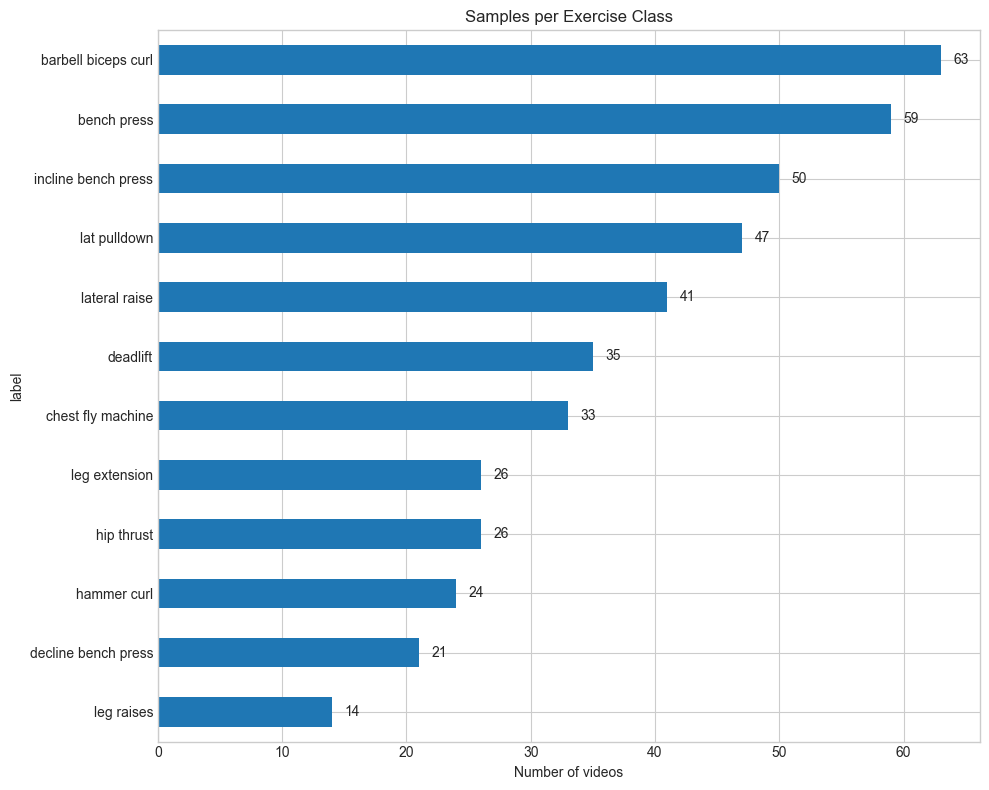


Min samples: 14 (leg raises)
Max samples: 63 (barbell biceps curl)
Mean: 37, Std: 16


In [5]:
# Samples per class
class_counts = df['label'].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
class_counts.plot(kind='barh', ax=ax)
ax.set_xlabel('Number of videos')
ax.set_title('Samples per Exercise Class')
for i, v in enumerate(class_counts):
    ax.text(v + 1, i, str(v), va='center')
plt.tight_layout()
plt.show()

print(f'\nMin samples: {class_counts.min()} ({class_counts.idxmin()})')
print(f'Max samples: {class_counts.max()} ({class_counts.idxmax()})')
print(f'Mean: {class_counts.mean():.0f}, Std: {class_counts.std():.0f}')

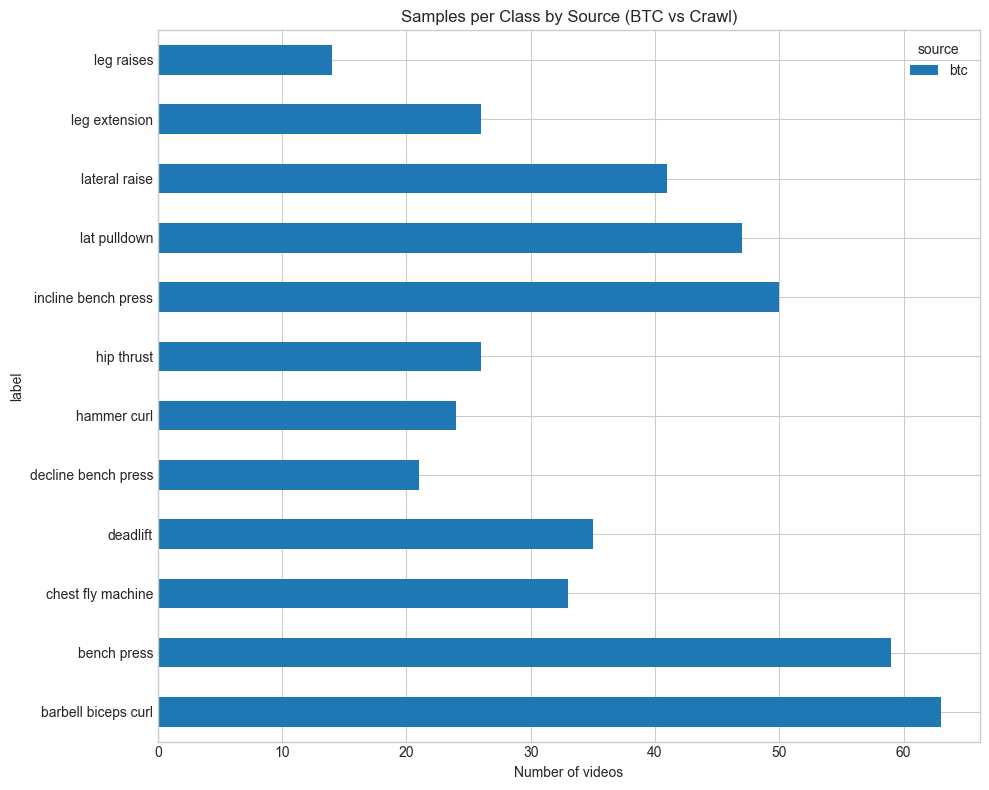

In [7]:
# Source distribution (btc vs crawl)
source_counts = df.groupby(['label', 'source']).size().unstack(fill_value=0)
source_counts.plot(kind='barh', stacked=True, figsize=(10, 8))
plt.xlabel('Number of videos')
plt.title('Samples per Class by Source (BTC vs Crawl)')
plt.tight_layout()
plt.show()

## 2. Feature Overview

In [8]:
# Feature columns (exclude metadata)
feature_cols = [c for c in df.columns if c not in ['video_path', 'label', 'source']]
print(f'Feature columns ({len(feature_cols)}):')
for c in feature_cols:
    print(f'  {c}')

print(f'\nBasic stats:')
df[feature_cols].describe().round(1)

Feature columns (37):
  left_knee_mean
  left_knee_std
  left_knee_min
  left_knee_max
  right_knee_mean
  right_knee_std
  right_knee_min
  right_knee_max
  left_hip_mean
  left_hip_std
  left_hip_min
  left_hip_max
  right_hip_mean
  right_hip_std
  right_hip_min
  right_hip_max
  left_elbow_mean
  left_elbow_std
  left_elbow_min
  left_elbow_max
  right_elbow_mean
  right_elbow_std
  right_elbow_min
  right_elbow_max
  left_shoulder_mean
  left_shoulder_std
  left_shoulder_min
  left_shoulder_max
  right_shoulder_mean
  right_shoulder_std
  right_shoulder_min
  right_shoulder_max
  torso_inclination_mean
  torso_inclination_std
  torso_inclination_min
  torso_inclination_max
  num_frames

Basic stats:


,left_knee_mean,left_knee_std,left_knee_min,left_knee_max,right_knee_mean,right_knee_std,right_knee_min,right_knee_max,left_hip_mean,left_hip_std,...,left_shoulder_max,right_shoulder_mean,right_shoulder_std,right_shoulder_min,right_shoulder_max,torso_inclination_mean,torso_inclination_std,torso_inclination_min,torso_inclination_max,num_frames
count,439.0,439.0,439.0,439.0,439.0,439.0,439.0,439.0,439.0,439.0,...,439.0,439.0,439.0,439.0,439.0,439.0,439.0,439.0,439.0,439.0
mean,138.6,21.5,76.4,169.9,138.2,21.6,78.1,169.8,139.8,20.9,...,98.8,51.5,23.4,11.6,98.4,29.8,11.3,13.6,59.7,144.5
std,33.0,17.1,59.1,23.9,34.8,17.3,58.3,24.0,30.3,19.1,...,57.1,34.8,17.1,17.7,56.2,36.4,16.4,29.2,58.4,96.3
min,0.4,0.0,0.0,0.4,18.1,0.0,0.1,31.2,7.1,0.0,...,4.5,2.4,0.0,0.0,5.7,0.3,0.0,0.0,0.3,1.0
25%,120.3,5.4,20.4,175.3,116.0,6.2,25.1,175.2,122.3,3.7,...,42.5,21.1,7.9,0.6,45.3,3.1,1.3,0.0,7.7,69.0
50%,143.6,19.1,66.2,179.4,143.6,18.6,70.3,179.6,146.3,16.2,...,96.3,48.1,21.4,4.7,96.7,10.4,3.1,0.7,38.6,120.0
75%,168.4,34.5,130.1,179.9,169.6,32.9,132.7,179.9,166.3,33.0,...,157.0,70.3,34.1,15.6,155.7,50.0,15.4,7.8,96.3,211.5
max,179.4,69.3,177.7,180.0,179.0,68.3,178.5,180.0,177.1,75.8,...,180.0,158.2,70.9,137.7,180.0,179.5,84.5,178.2,180.0,410.0


In [9]:
# Check for missing values
missing = df[feature_cols].isnull().sum()
if missing.sum() == 0:
    print('No missing values!')
else:
    print('Missing values:')
    print(missing[missing > 0])

No missing values!


## 3. Angle Distributions by Exercise

Compare mean angles across exercises to see which angles best separate classes.

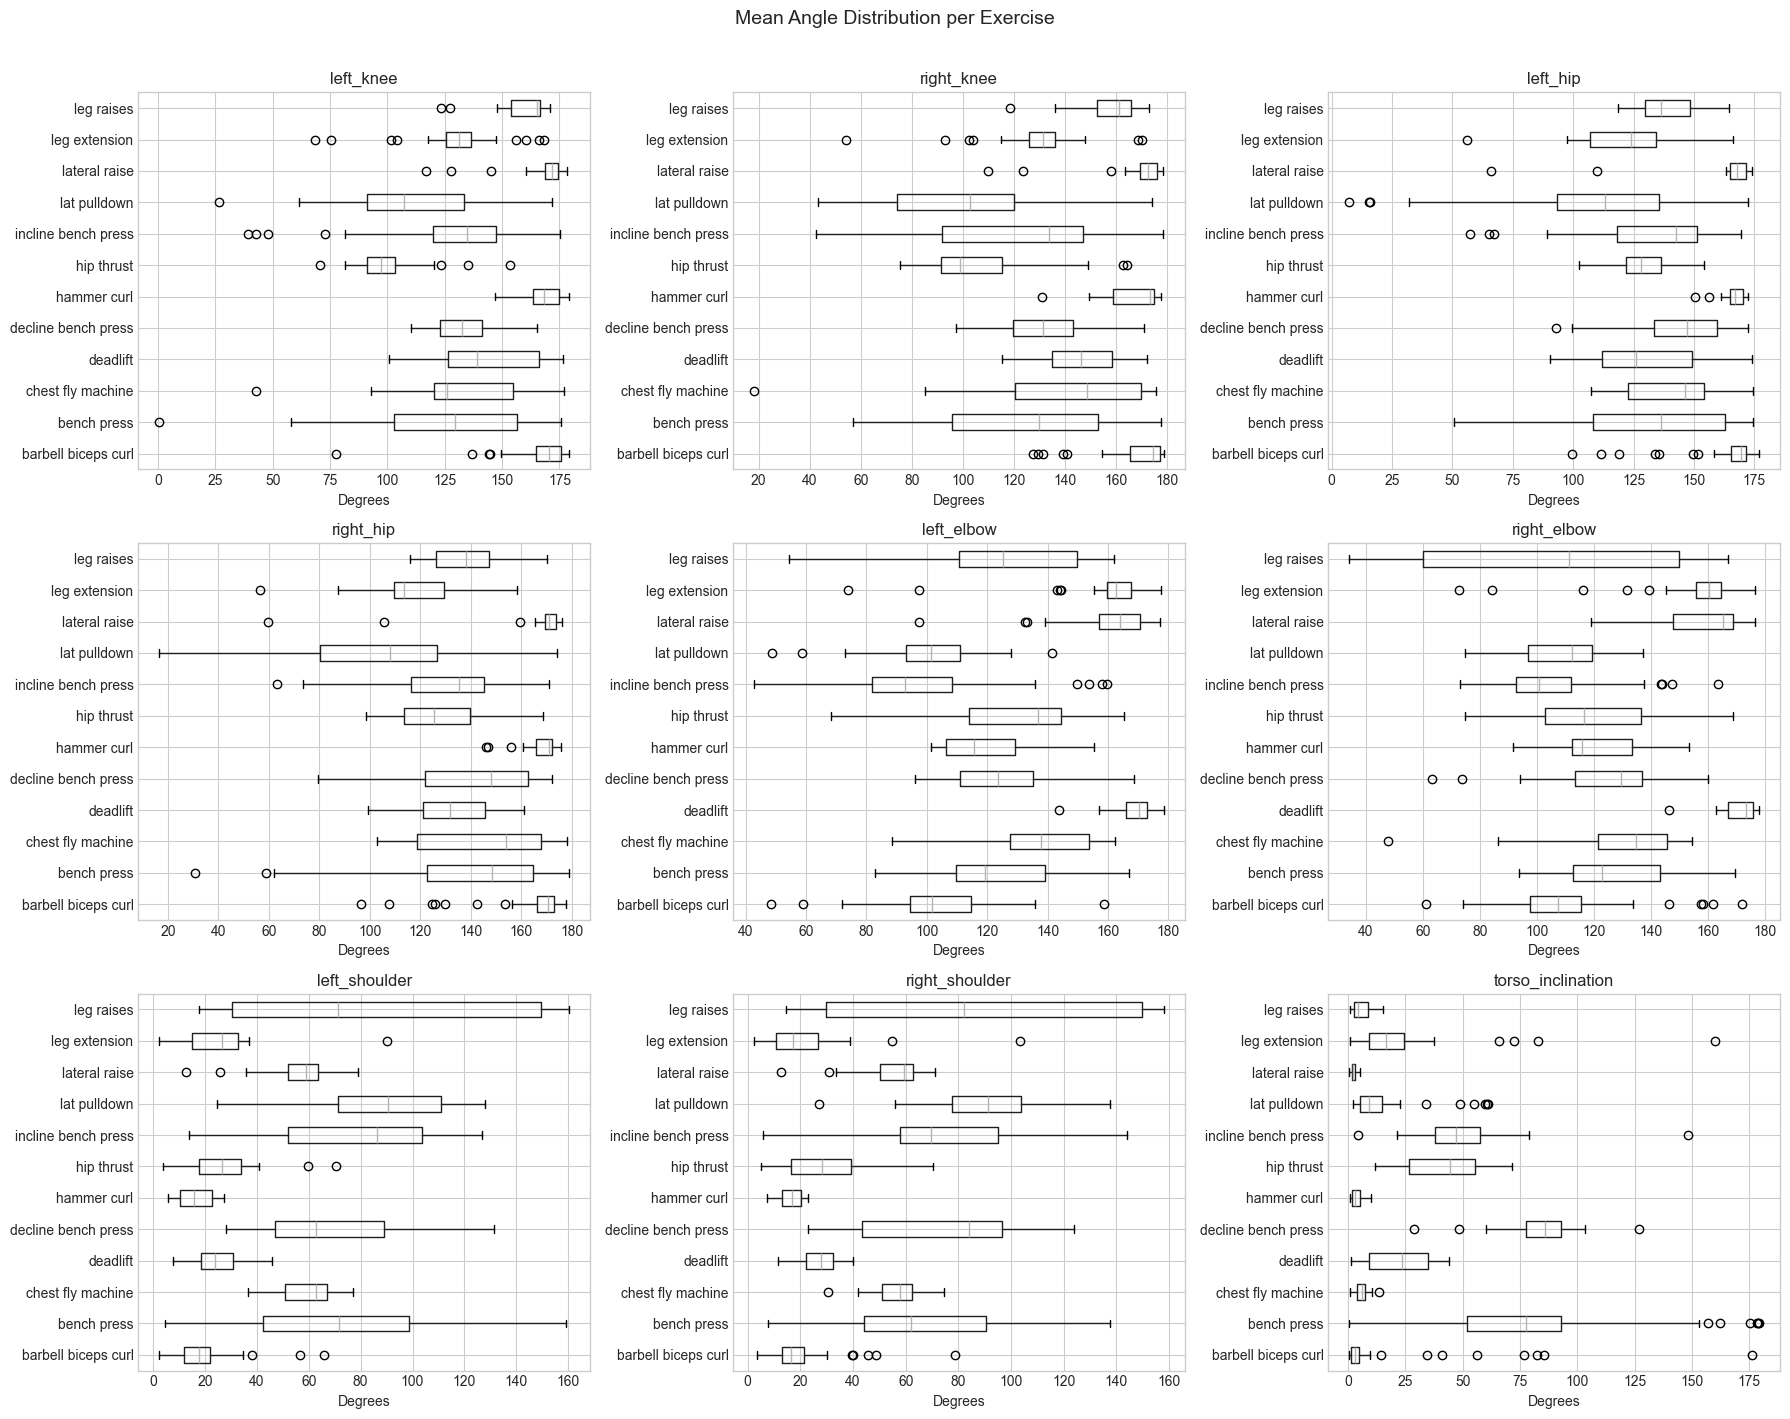

In [10]:
# Mean angle per exercise
angle_mean_cols = [c for c in feature_cols if c.endswith('_mean')]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(angle_mean_cols):
    angle_name = col.replace('_mean', '')
    ax = axes[i]
    
    # Box plot per exercise
    order = df.groupby('label')[col].median().sort_values().index
    df.boxplot(column=col, by='label', ax=ax, vert=False)
    ax.set_title(angle_name)
    ax.set_ylabel('')
    ax.set_xlabel('Degrees')

plt.suptitle('Mean Angle Distribution per Exercise', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 4. Range of Motion (Max - Min)

The difference between max and min angle shows how much each joint moves during the exercise.

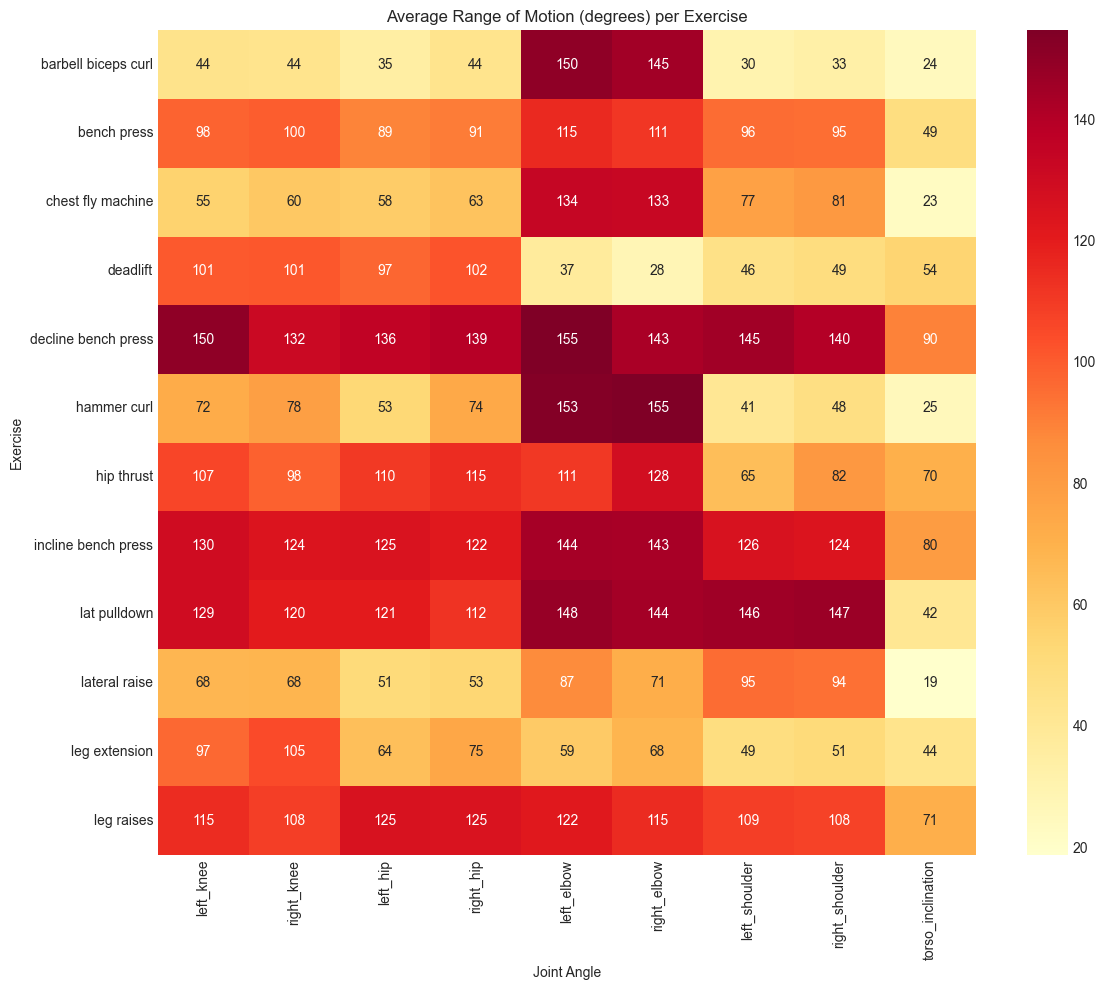

In [11]:
# Compute range of motion for each angle
angle_names = ['left_knee', 'right_knee', 'left_hip', 'right_hip',
               'left_elbow', 'right_elbow', 'left_shoulder', 'right_shoulder',
               'torso_inclination']

for name in angle_names:
    df[f'{name}_range'] = df[f'{name}_max'] - df[f'{name}_min']

range_cols = [f'{name}_range' for name in angle_names]

# Heatmap: average range of motion per exercise per angle
rom_by_exercise = df.groupby('label')[range_cols].mean()
rom_by_exercise.columns = [c.replace('_range', '') for c in rom_by_exercise.columns]

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(rom_by_exercise, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax)
ax.set_title('Average Range of Motion (degrees) per Exercise')
ax.set_xlabel('Joint Angle')
ax.set_ylabel('Exercise')
plt.tight_layout()
plt.show()

## 5. Correlation Between Features

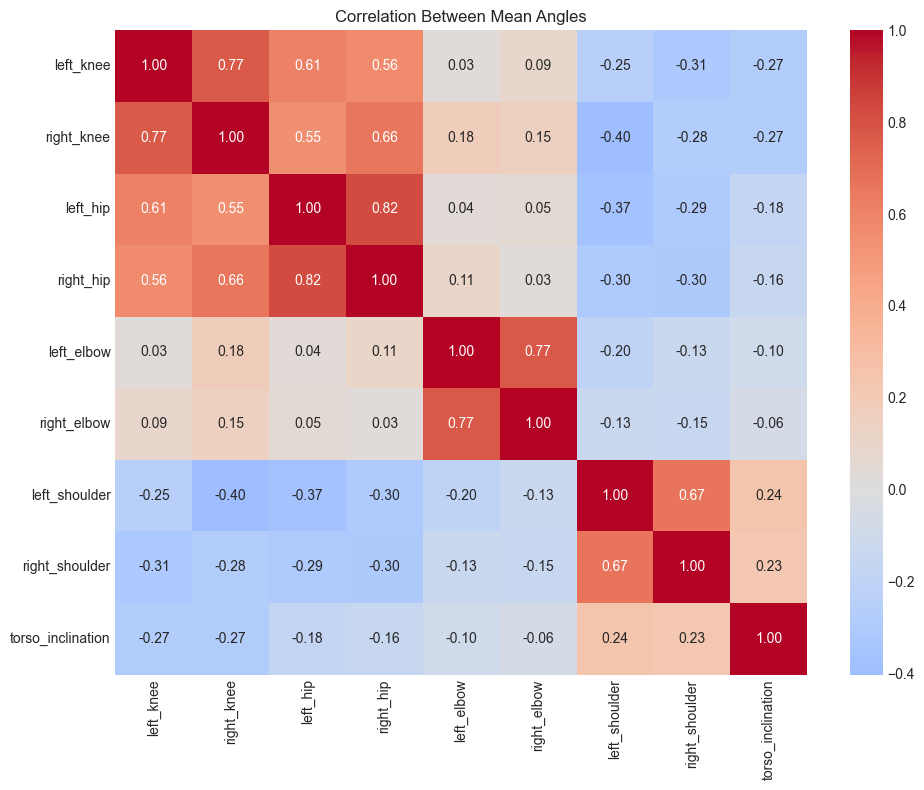

In [12]:
# Correlation matrix of mean angles
corr = df[angle_mean_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax,
            xticklabels=[c.replace('_mean', '') for c in angle_mean_cols],
            yticklabels=[c.replace('_mean', '') for c in angle_mean_cols])
ax.set_title('Correlation Between Mean Angles')
plt.tight_layout()
plt.show()

## 6. Torso Inclination — Standing vs Lying vs Bent

This is a key feature for separating exercise groups.

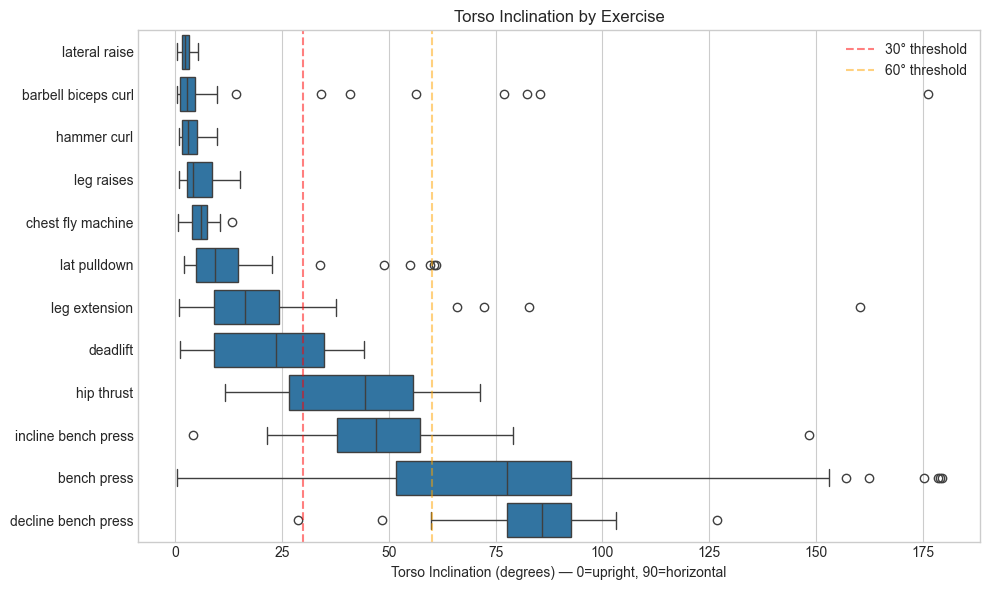

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
order = df.groupby('label')['torso_inclination_mean'].median().sort_values().index
sns.boxplot(data=df, y='label', x='torso_inclination_mean', order=order, ax=ax)
ax.set_xlabel('Torso Inclination (degrees) — 0=upright, 90=horizontal')
ax.set_ylabel('')
ax.set_title('Torso Inclination by Exercise')
ax.axvline(x=30, color='red', linestyle='--', alpha=0.5, label='30° threshold')
ax.axvline(x=60, color='orange', linestyle='--', alpha=0.5, label='60° threshold')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Frames Detected per Video

Check data quality — videos with very few frames may have poor pose detection.

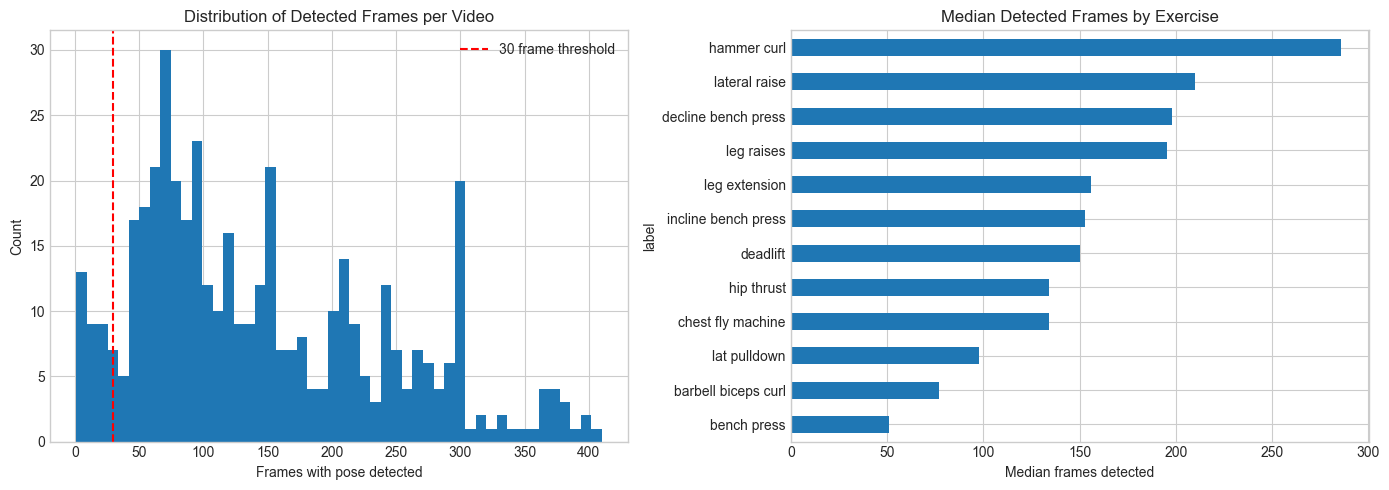

Videos with < 30 frames detected: 35 (8.0%)
label
bench press            17
barbell biceps curl     6
incline bench press     6
decline bench press     2
hip thrust              1
lat pulldown            1
lateral raise           1
leg extension           1
Name: count, dtype: int64


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
df['num_frames'].hist(bins=50, ax=axes[0])
axes[0].set_xlabel('Frames with pose detected')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Detected Frames per Video')
axes[0].axvline(x=30, color='red', linestyle='--', label='30 frame threshold')
axes[0].legend()

# Per class
df.groupby('label')['num_frames'].median().sort_values().plot(kind='barh', ax=axes[1])
axes[1].set_xlabel('Median frames detected')
axes[1].set_title('Median Detected Frames by Exercise')

plt.tight_layout()
plt.show()

low_frames = df[df['num_frames'] < 30]
print(f'Videos with < 30 frames detected: {len(low_frames)} ({100*len(low_frames)/len(df):.1f}%)')
if len(low_frames) > 0:
    print(low_frames['label'].value_counts())

## 8. Quick Separability Check (PCA)

Project all features to 2D to see if classes form clusters.

/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: inval

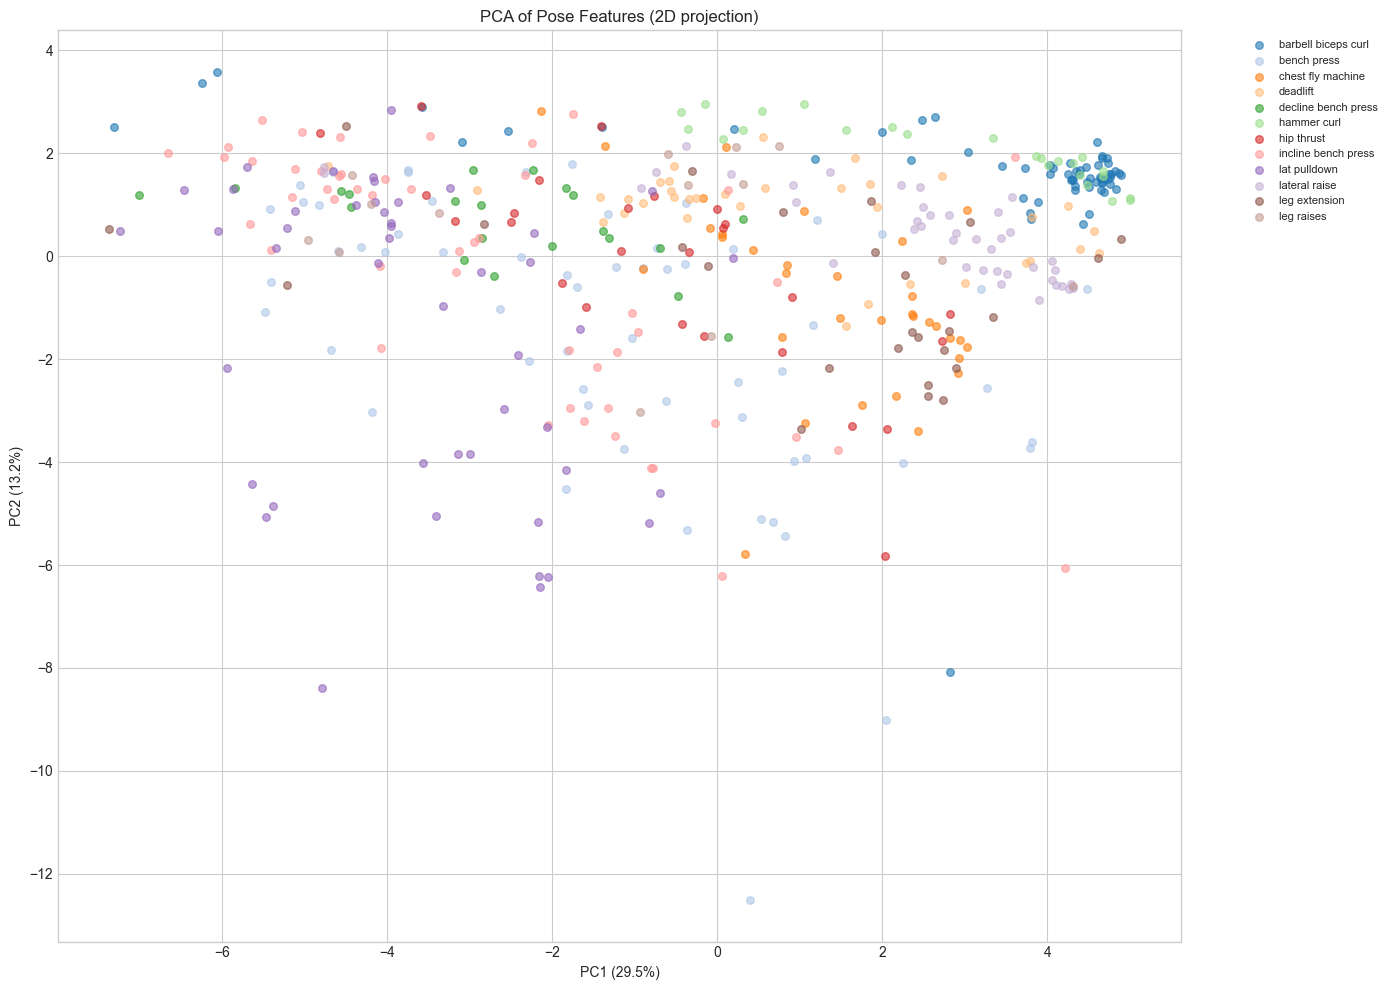

Variance explained by 2 components: 42.7%


In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df[feature_cols].values
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(14, 10))
labels = df['label'].values
unique_labels = sorted(df['label'].unique())

for label in unique_labels:
    mask = labels == label
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], label=label, alpha=0.6, s=30)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('PCA of Pose Features (2D projection)')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

print(f'Variance explained by 2 components: {pca.explained_variance_ratio_.sum()*100:.1f}%')